# Publications over the years

- Data processing for this particular study: we save the publications per years in different files, in data/processed.
- Plot area chart of the publications over the years, for different topics.

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import os
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

# Base paths for data
DATA = Path("../data")
EXTERNAL = DATA / "external"
PROCESSED = DATA / "processed" / "per_years"
PROCESSED.mkdir(parents=True, exist_ok=True) # create folders if they don't exist

### PRIMARY FILE: papers_cleaned.gencat.parquet

In [2]:
# DATASET: papers_cleaned.gencat.parquet
# Source: Dades obertes de la Generalitat de Catalunya
# Description: cleaned catalan publications
file_path = EXTERNAL / "papers_cleaned.gencat.parquet"

### Load data

In [5]:
def load_local_parquet(path):
    """Carrega un fitxer parquet local."""
    if not path.exists():
        raise FileNotFoundError(f"No s'ha trobat el fitxer: {path}")
    return pd.read_parquet(path)

# Load our data from dataset 'papers_cleaned.gencat.parquet'
df = load_local_parquet(file_path)
print(f"Carregades {len(df)} files.")

Carregades 1747707 files.


### Checks (and exploration)
We do a check and explore the columns/raws we have in our data

In [11]:
def profile(df):
    "To avoid error in the cells where there are lists (authors), we convert them into string"
    df_temp = df.copy()
    # Convert all the columns into strings (to avoid errors in lists, arrays...)
    for col in df_temp.columns:
        try:
            df_temp[col] = df_temp[col].astype(str)
        except Exception:
            pass
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing": (100 * df.isna().mean()).round(1),
        "n_unique": df_temp.nunique(),
    })

# Print data profile
display(profile(df))
# Print the first raws to explore the data we have
display(df.head())

,dtype,n_missing,pct_missing,n_unique
date,object,0,0.0,11123
doi,object,0,0.0,358039
ruct,object,0,0.0,88888
orcidResearchers,object,0,0.0,824070
orcidUncheckedAuthors,object,1623199,92.9,15920
orcidDirectors,object,1744810,99.8,64


,date,doi,ruct,orcidResearchers,orcidUncheckedAuthors,orcidDirectors
0,1949-01-01T00:00:00.000,10.1210/jcem-9-9-883,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
1,1952-01-01T00:00:00.000,10.1002/cber.19520850704,Universitat Rovira i Virgili,[0000-0001-6112-5913],None,None
2,1952-01-01T00:00:00.000,10.1111/j.1365-2133.1952.tb15900.x,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
3,1953-01-01T00:00:00.000,10.1038/jid.1953.55,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None
4,1954-01-01T00:00:00.000,10.1016/s0022-5347(17)67795-4,Universitat Rovira i Virgili,[0000-0002-6245-7933],None,None


### Data processing

We separate all the publications in different files per years, and we conserve the following columns: date, DOI.

In [14]:
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year.astype(int) # from the date, we only want the year

# Order years
anys_disponibles = sorted(df['year'].unique())

# Loop to create folders and files per year
for any_pub in anys_disponibles:

    # Filter the rows of this year
    df_any = df[df['year'] == any_pub]

    # Create and save file
    nom_fitxer = f"{any_pub}_publications.parquet"
    ruta_final = PROCESSED / nom_fitxer
    df_any.to_parquet(ruta_final, index=False)
    print(f"Desat: {nom_fitxer} ({len(df_any)} files)")

print(f"\nFet! S'han creat {len(anys_disponibles)} fitxers a la carpeta '{PROCESSED.resolve()}'.")

Desat: 1949_publications.parquet (1 files)
Desat: 1952_publications.parquet (2 files)
Desat: 1953_publications.parquet (1 files)
Desat: 1954_publications.parquet (2 files)
Desat: 1956_publications.parquet (1 files)
Desat: 1957_publications.parquet (1 files)
Desat: 1959_publications.parquet (1 files)
Desat: 1961_publications.parquet (2 files)
Desat: 1962_publications.parquet (3 files)
Desat: 1964_publications.parquet (1 files)
Desat: 1966_publications.parquet (1 files)
Desat: 1967_publications.parquet (1 files)
Desat: 1969_publications.parquet (6 files)
Desat: 1970_publications.parquet (36 files)
Desat: 1972_publications.parquet (7 files)
Desat: 1973_publications.parquet (14 files)
Desat: 1974_publications.parquet (19 files)
Desat: 1975_publications.parquet (18 files)
Desat: 1976_publications.parquet (26 files)
Desat: 1977_publications.parquet (41 files)
Desat: 1978_publications.parquet (51 files)
Desat: 1979_publications.parquet (87 files)
Desat: 1980_publications.parquet (126 files)
D

### PLOT 1: all publications over the years

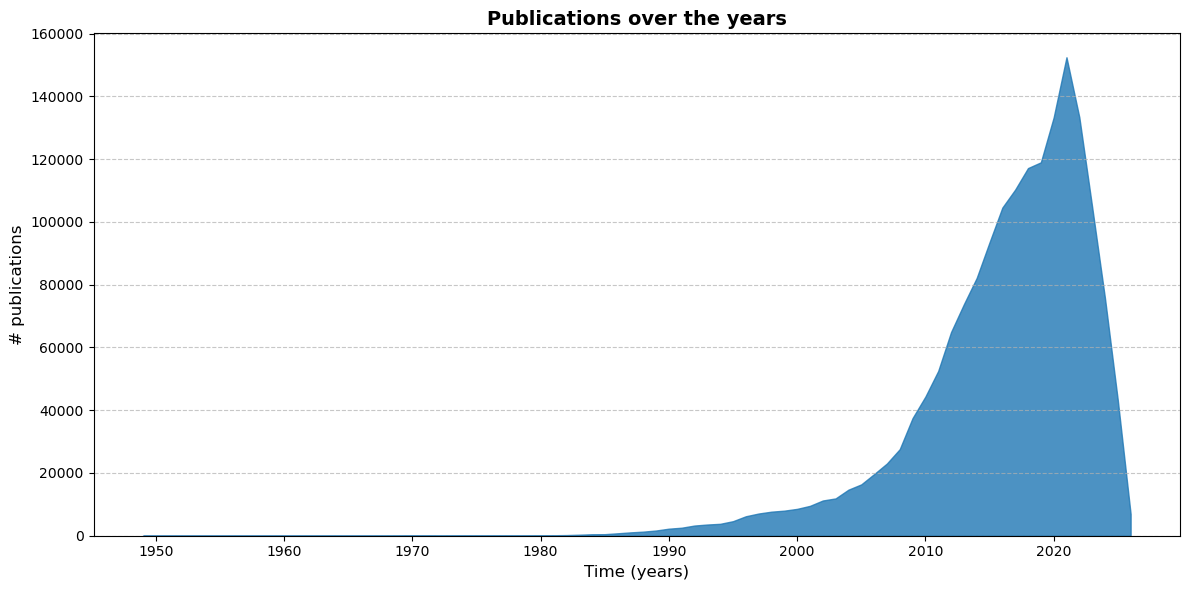

In [17]:
# Counts publications per year
publicacions_per_any = df['year'].value_counts().sort_index()

anys = publicacions_per_any.index
quantitat = publicacions_per_any.values

# PLOT
plt.figure(figsize=(12, 6))
plt.stackplot(anys, quantitat, labels=['Total publicacions'], color='#1f77b4', alpha=0.8)
plt.title("Publications over the years", fontsize=14, fontweight='bold')
plt.xlabel("Time (years)", fontsize=12)
plt.ylabel("# publications", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
#plt.legend(loc='upper left')
plt.tight_layout()

plt.show()

### SECONDARY FILES: fields.parquet, works.parquet

In [22]:
# FIELDS (fields.parquet)

fields_df = pd.read_parquet("../data/external/fields.parquet")

print("Columnes:", fields_df.columns.tolist())
print(f"Dimensions: {fields_df.shape[0]} files i {fields_df.shape[1]} columnes")

#display(fields_df.head()) # shows firsts raws
display(fields_df) # shows all raws 26)

Columnes: ['field_id', 'field_name', 'domain_id', 'domain_name']
Dimensions: 26 files i 4 columnes


,field_id,field_name,domain_id,domain_name
0,33,Social Sciences,2,Social Sciences
1,31,Physics and Astronomy,3,Physical Sciences
2,27,Medicine,4,Health Sciences
3,12,Arts and Humanities,2,Social Sciences
4,11,Agricultural and Biological Sciences,1,Life Sciences
5,22,Engineering,3,Physical Sciences
6,17,Computer Science,3,Physical Sciences
7,23,Environmental Science,3,Physical Sciences
8,14,"Business, Management and Accounting",2,Social Sciences
9,13,"Biochemistry, Genetics and Molecular Biology",1,Life Sciences


In [23]:
# WORKS (works.parquet)

works_df = pd.read_parquet("../data/external/works.parquet")

print(f"Dimensions: {works_df.shape[0]} files, {works_df.shape[1]} columnes")
print("Columnes:", works_df.columns.tolist())

display(works_df.head(2))

Dimensions: 348417 files, 9 columnes
Columnes: ['openalex_id', 'doi', 'apc_paid_value_usd', 'apc_list_value_usd', 'awards', 'funders', 'primary_topic_field_id', 'topics_field_ids', 'referenced_works']


,openalex_id,doi,apc_paid_value_usd,apc_list_value_usd,awards,funders,primary_topic_field_id,topics_field_ids,referenced_works
0,W2052543964,10.1021/ja01036a083,NaN,4500.0,[],[],16,[],[]
1,W2917211058,10.1016/j.patrec.2019.02.029,NaN,2550.0,[],[],17,[],[]


### Cross data

In [ ]:
PROCESSED = Path("../data/processed")
PER_YEARS = PROCESSED / "per_years"

# Join all files per years in one temporary variable called df_total
llista_dfs = [pd.read_parquet(f) for f in PER_YEARS.glob("*_publications.parquet")]
df_total = pd.concat(llista_dfs, ignore_index=True)

# 📊 COMPTATGE DE DUPLICATS 1: A les dades originals
total_files_originals = len(df_total)
dois_unics_originals = df_total["doi"].nunique()
duplicats_originals = total_files_originals - dois_unics_originals

print(f"Files originals: {total_files_originals}")
print(f"DOIs únics: {dois_unics_originals}")
print(f"Duplicats detectats a l'origen: {duplicats_originals}")

# Load data (fields, domains..)
works = pd.read_parquet("../data/external/works.parquet", columns=["doi", "primary_topic_field_id", "topics_field_ids"])
fields = pd.read_parquet("../data/external/fields.parquet")

# Force that IDs are text to merge them correctly
works["primary_topic_field_id"] = works["primary_topic_field_id"].astype(str)
fields["field_id"] = fields["field_id"].astype(str)

# Create diccionaries to traduce IDs into names
field_to_domain = dict(zip(fields["field_id"], fields["domain_name"]))
field_to_name = dict(zip(fields["field_id"], fields["field_name"]))

# Merge works to the df_total (doi,date)
df_complet = df_total.merge(works, on="doi", how="left") # merge 'left' to conserve all papers

# Add domains and topics names
df_complet["domain_name"] = df_complet["primary_topic_field_id"].map(field_to_domain)
df_complet["field_name"] = df_complet["primary_topic_field_id"].map(field_to_name)

# Select only the columns we want
columnes_finals = ["year", "doi", "domain_name", "field_name", "topics_field_ids"]
df_final = df_complet[columnes_finals]

# Save the file: all_publications_enriched.parquet
output_path = PROCESSED / "all_publications_enriched.parquet"
df_final.to_parquet(output_path, index=False)

print(f"Dimensions: {df_final.shape[0]} files, {df_final.shape[1]} columnes")
print(f"Columnes: {df_final.columns.tolist()}")

# Count papers with and without topic and print nums
total_papers = len(df_final)
papers_sense_topic = df_final["domain_name"].isna().sum()
papers_amb_topic = total_papers - papers_sense_topic

print(f"Total de papers (sense tocar res): {total_papers}")
print(f"Papers SENSE topic assignat: {papers_sense_topic}")
print(f"Papers AMB topic assignat: {papers_amb_topic}")
print(f"Percentatge de papers sense topic: {(papers_sense_topic / total_papers) * 100:.2f}%")

Dimensions: 1749314 files, 5 columnes
Columnes: ['year', 'doi', 'domain_name', 'field_name', 'topics_field_ids']
Total de papers (sense tocar res): 1749314
Papers SENSE topic assignat: 30242
Papers AMB topic assignat: 1719072
Percentatge de papers sense topic: 1.73%
